# Baseline: regresión logística simple

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro

---

### Abstract

Este notebook entrena la referencia contra la que se comparan los cuatro modelos del proyecto: una **regresión logística sin balanceo de clases y sin ajuste de hiperparámetros** (`C=1`), que corresponde al modelo "sin balanceo" de Almeida et al. (2026). Usa las 9 features del EDA, casos completos y la partición temporal (train y validación 2015–2023, test 2024–2025). Se reportan AUC-ROC y AUC-PR, que no dependen del umbral, y precisión, recall y F1 con el umbral por defecto de 0.5, como en los papers.

**Resultado principal:** en el test (2024–2025) el baseline alcanza AUC-ROC 0.908 y AUC-PR 0.677 (unas 10 veces el azar), pero con el umbral 0.5 solo detecta 47% de los casos de bajo peso (precisión 0.82).

### Estructura del notebook

1. Configuración del entorno
2. Datos y partición temporal
3. Modelo baseline
4. Evaluación en validación y test
5. Interpretación
6. Limitaciones

## 1. Configuración del entorno

El notebook funciona en Google Colab y en local, igual que el EDA. En Colab clona o actualiza el repositorio; en local asume que se ejecuta desde `proyecto/notebooks/`. Todo el preprocesamiento se importa de `src/preprocessing.py`, para que los cinco modelos usen exactamente los mismos datos y la misma partición.

In [ ]:
import sys, gc, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasnai10/AI_Project.git"

if IN_COLAB:
    if not Path("/content/AI_Project").exists():
        !git clone -q {REPO_URL} /content/AI_Project
    else:
        !git -C /content/AI_Project pull -q
    ROOT = Path("/content/AI_Project/proyecto")
else:
    ROOT = Path.cwd().parent

sys.path.insert(0, str(ROOT))
from src.preprocessing import (cargar_cnv, limpiar, seleccionar_features, columnas_features,
                               dividir_temporal, construir_preprocesador, SEMILLA)

pd.set_option("display.float_format", "{:,.4f}".format)
print("Entorno:", "Colab" if IN_COLAB else "local", "| ROOT:", ROOT)

Entorno: Colab | ROOT: /content/AI_Project/proyecto


## 2. Datos y partición temporal

Se carga el CNV original desde `data/raw/dataset.zip` y se aplican `limpiar()` y `seleccionar_features()` (9 features, casos completos). La partición es la **temporal** definida en el EDA:

| Conjunto | Años | Uso |
|---|---|---|
| Train | 2015–2023 (80% al azar, estratificado) | Ajustar el modelo y el preprocesador |
| Validación | 2015–2023 (20% restante) | Comparar con el test (estabilidad en el tiempo) |
| Test | 2024–2025 | Evaluación final, una sola vez |

El test simula el uso real: entrenar con el pasado y predecir el futuro. Su prevalencia (6.81%) es mayor que la de train (6.32%), así que la precisión y el F1 en test cambian de nivel aunque el modelo sea el mismo. Por eso los modelos se comparan sobre todo con métricas que no dependen de la prevalencia ni del umbral. 2025 llega hasta el 30/11/2025, sin diciembre.

In [ ]:
df_raw, _ = cargar_cnv(ruta_zip=ROOT / "data" / "raw" / "dataset.zip")
df = limpiar(df_raw)
del df_raw; gc.collect()

X, y = seleccionar_features(df, target="bajo_peso")
X_tr, X_val, X_te, y_tr, y_val, y_te = dividir_temporal(X, y, df["anio"])
anio = df["anio"]
resumen = pd.DataFrame({
    "años": [f"{anio[X_tr.index].min()}-{anio[X_tr.index].max()}",
             f"{anio[X_val.index].min()}-{anio[X_val.index].max()}",
             f"{anio[X_te.index].min()}-{anio[X_te.index].max()}"],
    "registros": [len(y_tr), len(y_val), len(y_te)],
    "casos_bajo_peso": [int(y_tr.sum()), int(y_val.sum()), int(y_te.sum())],
    "prevalencia_%": [y_tr.mean() * 100, y_val.mean() * 100, y_te.mean() * 100]},
    index=["train", "validación", "test"])
del X, y, df, anio; gc.collect()
cat_cols, num_cols = columnas_features()
resumen.round(2)

Cargado CNV_MINSA_CORTE_30112025.csv: 4,874,510 filas, 22 columnas | filas reparadas: 388 | descartadas: 0
limpiar(): 4,874,510 → 4,871,486 filas (eliminadas 3,024 sin peso válido) | prevalencia de bajo peso: 6.38%
target=bajo_peso | 9 features | casos completos: 4,764,960 de 4,871,486 (97.81%)


,años,registros,casos_bajo_peso,prevalencia_%
train,2015-2023,3237829,204500,6.3200
validación,2015-2023,809458,51125,6.3200
test,2024-2025,717673,48907,6.8100


## 3. Modelo baseline

Regresión logística con regularización L2, `C=1` (valor por defecto) y solver `lbfgs`, **sin `class_weight` y sin ajuste de hiperparámetros**. Un baseline debe ser simple y no depender de decisiones de modelado: es el punto de partida para medir qué aportan el balanceo (notebooks 03 y 04) y los modelos de árboles (05 y 06).

El preprocesador es el de `src/preprocessing.py` (one-hot para las 7 categóricas y estandarización para `Num_embar_madre` y `DUR_EMB_PARTO`, 53 columnas) y se ajusta solo con train, dentro del `Pipeline`.

### Métricas

- **AUC-ROC y AUC-PR:** no dependen del umbral. Son las métricas principales para comparar modelos. El AUC-PR de un clasificador al azar es igual a la prevalencia (0.0681 en test), no a 0.5.
- **Precisión, recall y F1 con umbral 0.5:** el umbral **no se calibra**, igual que en Almeida et al. (2026), Khan et al. (2022) y Ranjbar et al. (2023), que usaron el valor por defecto de sus librerías. Así las cifras son comparables con las de los papers.
- **Accuracy:** solo como referencia. Con 6-7% de prevalencia, predecir siempre "no bajo peso" ya da cerca de 93%.

In [ ]:
UMBRAL = 0.5

def evaluar(y_true, p, umbral=UMBRAL):
    pred = (p >= umbral).astype(int)
    return {"auc_roc": roc_auc_score(y_true, p),
            "auc_pr": average_precision_score(y_true, p),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "accuracy": accuracy_score(y_true, pred)}

t0 = time.time()
baseline = Pipeline([("prep", construir_preprocesador()),
                     ("clf", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=SEMILLA))])
baseline.fit(X_tr, y_tr)
print(f"Baseline ajustado en {time.time() - t0:.0f} s con {len(y_tr):,} registros")

Baseline ajustado en 13 s con 3,237,829 registros


## 4. Evaluación en validación y test

La validación (2015–2023) y el test (2024–2025) se evalúan con el mismo modelo. Si las métricas que no dependen de la prevalencia (AUC-ROC, AUC-PR relativo al azar) se mantienen, el modelo generaliza en el tiempo.

In [ ]:
p_val = baseline.predict_proba(X_val)[:, 1]
p_te = baseline.predict_proba(X_te)[:, 1]
metricas = pd.DataFrame({"validación (2015-2023)": evaluar(y_val, p_val), "test (2024-2025)": evaluar(y_te, p_te)}).T
metricas["prevalencia"] = [y_val.mean(), y_te.mean()]
metricas["auc_pr / prevalencia"] = metricas["auc_pr"] / metricas["prevalencia"]
display(metricas.round(4))

cm = confusion_matrix(y_te, (p_te >= UMBRAL).astype(int))
print("Matriz de confusión en test, umbral 0.5 [[TN FP], [FN TP]]:", cm.tolist())
print(f"Detecta {cm[1, 1]:,} de {int(y_te.sum()):,} casos de bajo peso, con {cm[0, 1]:,} falsas alarmas.")

,auc_roc,auc_pr,precision,recall,f1,accuracy,prevalencia,auc_pr / prevalencia
validación (2015-2023),0.9044,0.6666,0.8264,0.4619,0.5926,0.9599,0.0632,10.5538
test (2024-2025),0.9081,0.6774,0.8204,0.4732,0.6002,0.9570,0.0681,9.9398


Matriz de confusión en test, umbral 0.5 [[TN FP], [FN TP]]: [[663699, 5067], [25763, 23144]]
Detecta 23,144 de 48,907 casos de bajo peso, con 5,067 falsas alarmas.


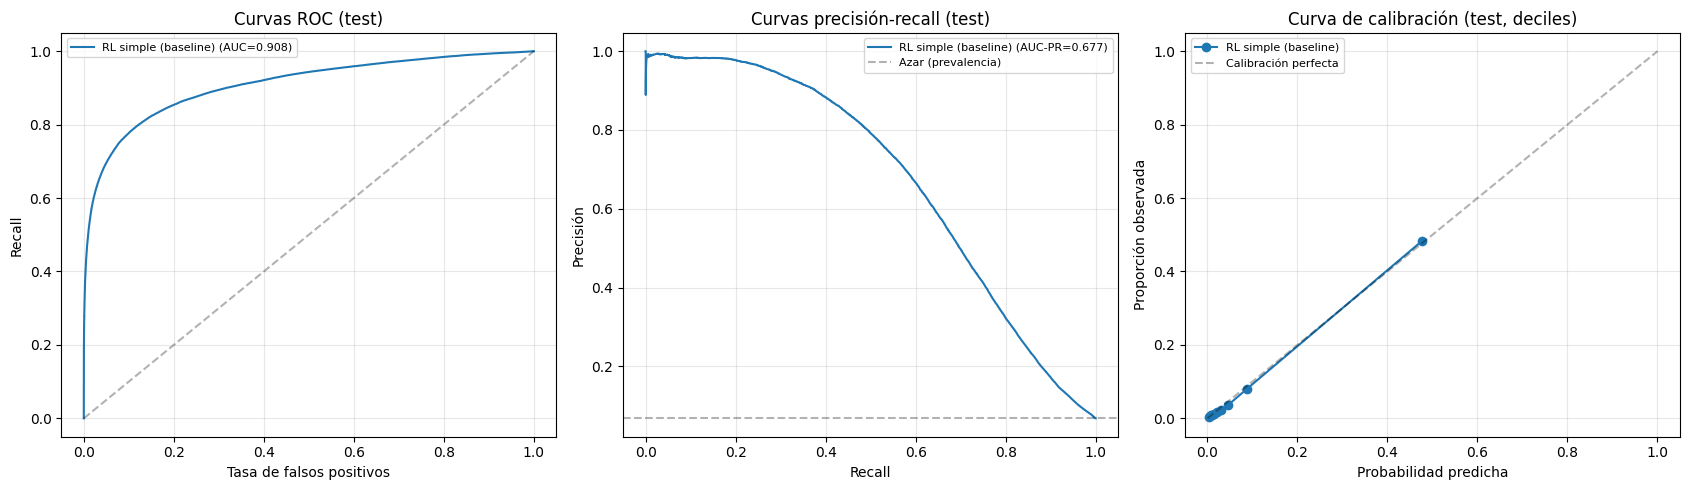

In [ ]:
probas_te = {"RL simple (baseline)": p_te}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k, p in probas_te.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{k} (AUC={roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rc, pr, label=f"{k} (AUC-PR={average_precision_score(y_te, p):.3f})")
    frac, media = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(media, frac, "o-", label=k)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.3)
axes[0].set(title="Curvas ROC (test)", xlabel="Tasa de falsos positivos", ylabel="Recall")
axes[1].axhline(y_te.mean(), color="k", ls="--", alpha=.3, label="Azar (prevalencia)")
axes[1].set(title="Curvas precisión-recall (test)", xlabel="Recall", ylabel="Precisión")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.3, label="Calibración perfecta")
axes[2].set(title="Curva de calibración (test, deciles)", xlabel="Probabilidad predicha", ylabel="Proporción observada")
for a in axes:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Interpretación

Las cifras corresponden a la ejecución de referencia; los valores exactos están en las tablas de arriba.

**1. El baseline ya discrimina bien.** En el test (2024–2025) alcanza AUC-ROC 0.908 y AUC-PR 0.677, unas 10 veces el AUC-PR de un clasificador al azar (la prevalencia, 0.068). Cualquier modelo de los notebooks 03 a 06 tiene que superar estas cifras para justificar su complejidad.

**2. Generaliza en el tiempo.** Entre validación (2015–2023) y test (2024–2025), el AUC-ROC pasa de 0.904 a 0.908 y el AUC-PR de 0.667 a 0.677. La subida del AUC-PR se explica sobre todo por la mayor prevalencia del test: relativo al azar baja levemente (de 10.6 a 9.9 veces). El modelo entrenado con el pasado mantiene su capacidad de discriminar en los años siguientes.

**3. Con el umbral 0.5 detecta menos de la mitad de los casos.** En test, la precisión es 0.82 pero el recall es 0.47: detecta 23 144 de 48 907 casos de bajo peso y deja 25 763 sin detectar, con solo 5 067 falsas alarmas. No es un problema de discriminación sino del umbral: con una prevalencia de 6.8%, pocas probabilidades superan 0.5 (incluso el 10% de registros con mayor riesgo tiene una probabilidad media cercana a 0.48, según la curva de calibración). Esto es lo que los notebooks 03 y 04 cambian al tratar el desbalance.

**4. Las probabilidades están bien calibradas.** En la curva de calibración, los deciles de probabilidad predicha coinciden con la proporción observada de bajo peso. Una regresión logística sin balanceo estima bien el riesgo absoluto; los modelos balanceados, en cambio, inflan las probabilidades.

## 6. Limitaciones

- **`DUR_EMB_PARTO` se conoce al momento del parto, no antes.** El encuadre es "información registrada al momento del parto, antes del pesaje"; no es una predicción prenatal.
- **Umbral fijo en 0.5**, como en los papers. Precisión, recall y F1 dependen de esa elección; AUC-ROC y AUC-PR no.
- **La prevalencia del test (6.81%) es mayor que la de train (6.32%).** Precisión y F1 en test no son directamente comparables con validación.
- **El peso tiene redondeo en 2500 g** (16 353 registros exactos), lo que mete ruido en la etiqueta justo en el umbral.
- **El test no incluye diciembre de 2025.**
- **El CNV no registra variables clínicas** (controles prenatales, anemia, hipertensión, IMC), que podrían mejorar la predicción.
- El baseline no tiene ajuste de hiperparámetros ni tratamiento del desbalance, a propósito: esas decisiones se evalúan en los notebooks 03 a 06.